<a href="https://colab.research.google.com/github/barajascamposluisjavier-ship-it/eserci-n-escolar-exito-academico/blob/main/Desercion_escolar.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicción de Deserción Escolar y Éxito Académico

Este notebook forma parte del proyecto enfocado en resolver una problemática crítica para las instituciones de educación superior: la deserción escolar y el bajo rendimiento académico.

Utilizando técnicas de ciencia de datos y aprendizaje automático, este sistema busca anticiparse a los casos de riesgo antes de que los alumnos abandonen definitivamente sus estudios.

**Este cuaderno está organizado en las siguientes etapas clave para guiar el análisis y el modelado predictivo:**

1. Carga del Dataset: Importación de la base de datos de Kaggle sobre predictores de retención estudiantil en educación superior.

2. Limpieza y Preprocesamiento: Depuración de valores nulos, separación de variables predictoras (X) y la variable objetivo (Target), asegurando que la información esté lista para los algoritmos.

3. División de Datos: Partición del conjunto de datos en subconjuntos de entrenamiento y prueba (80/20) para evaluar el rendimiento de manera objetiva.

4. Normalización / Escalamiento: Implementación de StandardScaler para nivelar las distintas escalas numéricas de las variables (como calificaciones y factores demográficos).

5. Entrenamiento del Modelo: Ajuste de un modelo de clasificación basado en Random Forest (RandomForestClassifier) para aprender patrones complejos de éxito y deserción.

6. Evaluación de Resultados: Generación de métricas de rendimiento (matriz de confusión y reporte de clasificación) para medir la precisión predictiva del modelo.

# Importación de librerías y montaje de Google Drive

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Carga del Dataset e inspección inicial (Head, Info, Describe)

In [ ]:
# Carga del dataset oficial de Kaggle
df_students = pd.read_csv('/content/dataset.csv')

In [ ]:
df_students.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,6,1,11,1,1,1,1,3,4,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,5,1,1,1,22,27,10,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,8,2,15,1,1,1,23,27,6,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,12,1,3,0,1,1,22,28,10,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [ ]:
#Inforamción de DATASET
df_students.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 35 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Nacionality                                     4424 non-null   int64  
 7   Mother's qualification                          4424 non-null   int64  
 8   Father's qualification                          4424 non-null   int64  
 9   Mother's occupation                      

In [ ]:
# Descripción estadística básica
df_students.describe()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
count,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,...,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000,4424.000000
mean,1.178571,6.886980,1.727848,9.899186,0.890823,2.531420,1.254521,12.322107,16.455244,7.317812,...,0.137658,0.541817,6.232143,8.063291,4.435805,10.230206,0.150316,11.566139,1.228029,0.001969
std,0.605747,5.298964,1.313793,4.331792,0.311897,3.963707,1.748447,9.026251,11.044800,3.997828,...,0.690880,1.918546,2.195951,3.947951,3.014764,5.210808,0.753774,2.663850,1.382711,2.269935
min,1.000000,1.000000,0.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,7.600000,-0.800000,-4.060000
25%,1.000000,1.000000,1.000000,6.000000,1.000000,1.000000,1.000000,2.000000,3.000000,5.000000,...,0.000000,0.000000,5.000000,6.000000,2.000000,10.750000,0.000000,9.400000,0.300000,-1.700000
50%,1.000000,8.000000,1.000000,10.000000,1.000000,1.000000,1.000000,13.000000,14.000000,6.000000,...,0.000000,0.000000,6.000000,8.000000,5.000000,12.200000,0.000000,11.100000,1.400000,0.320000
75%,1.000000,12.000000,2.000000,13.000000,1.000000,1.000000,1.000000,22.000000,27.000000,10.000000,...,0.000000,0.000000,7.000000,10.000000,6.000000,13.333333,0.000000,13.900000,2.600000,1.790000
max,6.000000,18.000000,9.000000,17.000000,1.000000,17.000000,21.000000,29.000000,34.000000,32.000000,...,12.000000,19.000000,23.000000,33.000000,20.000000,18.571429,12.000000,16.200000,3.700000,3.510000


# Verificación de nulos, duplicados y tipos de datos

In [ ]:
df_students.isnull().sum()
# No hay valores nulos

,0
Marital status,0
Application mode,0
Application order,0
Course,0
Daytime/evening attendance,0
Previous qualification,0
Nacionality,0
Mother's qualification,0
Father's qualification,0
Mother's occupation,0


In [ ]:
# Verificar registros duplicados
df_students.duplicated().sum()

np.int64(0)

In [ ]:
df_students.dtypes

,0
Marital status,int64
Application mode,int64
Application order,int64
Course,int64
Daytime/evening attendance,int64
Previous qualification,int64
Nacionality,int64
Mother's qualification,int64
Father's qualification,int64
Mother's occupation,int64


In [ ]:
# Muestra el resumen estadístico transpuesto y redondeado a 2 decimales
display(df_students[['Curricular units 1st sem (grade)', 'Unemployment rate', 'Inflation rate', 'GDP']].describe().T.round())

,count,mean,std,min,25%,50%,75%,max
Curricular units 1st sem (grade),4424.0,0.0,1.0,-2.20,0.07,0.34,0.57,1.70
Unemployment rate,4424.0,-0.0,1.0,-1.49,-0.81,-0.18,0.88,1.74
Inflation rate,4424.0,0.0,1.0,-1.47,-0.67,0.12,0.99,1.79
GDP,4424.0,0.0,1.0,-1.79,-0.75,0.14,0.79,1.55


# Escalado de Variables Numéricas


In [ ]:
scaler = StandardScaler()

# Seleccionar únicamente columnas numéricas del dataset de estudiantes
num_cols = df_students.select_dtypes(include=[np.number]).columns

In [ ]:
# Aplicar el cambio directamente sobre df_students
df_students[num_cols] = scaler.fit_transform(df_students[num_cols])
df_students.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,-0.294829,0.210069,2.490896,-1.823744,0.350082,-0.386404,-0.145586,0.075111,-0.584526,-0.329669,...,-0.282442,-2.838337,-2.042630,-1.471527,-1.963489,-0.199441,-0.287638,0.124386,0.765761,Dropout
1,-0.294829,-0.167406,-0.554068,0.254153,0.350082,-0.386404,-0.145586,-1.254495,-1.218380,-0.829997,...,-0.282442,-0.105726,-0.522682,0.518904,0.659562,-0.199441,0.876222,-1.105222,0.347199,Graduate
2,-0.294829,-1.111094,2.490896,-1.131112,0.350082,-0.386404,-0.145586,1.072315,0.954834,0.670987,...,-0.282442,-0.105726,-2.042630,-1.471527,-1.963489,-0.199441,-0.287638,0.124386,0.765761,Dropout
3,-0.294829,0.210069,0.207173,1.177663,0.350082,-0.386404,-0.145586,1.183116,0.954834,-0.329669,...,-0.282442,-0.105726,0.490616,0.187165,0.416450,-0.199441,-0.813253,-1.466871,-1.375511,Graduate
4,1.356212,0.965018,-0.554068,-1.592866,-2.856470,-0.386404,-0.145586,1.072315,1.045384,0.670987,...,-0.282442,-0.105726,-0.522682,0.518904,0.531608,-0.199441,0.876222,-1.105222,0.347199,Graduate


# Matriz de Correlación (Mapa de Calor)

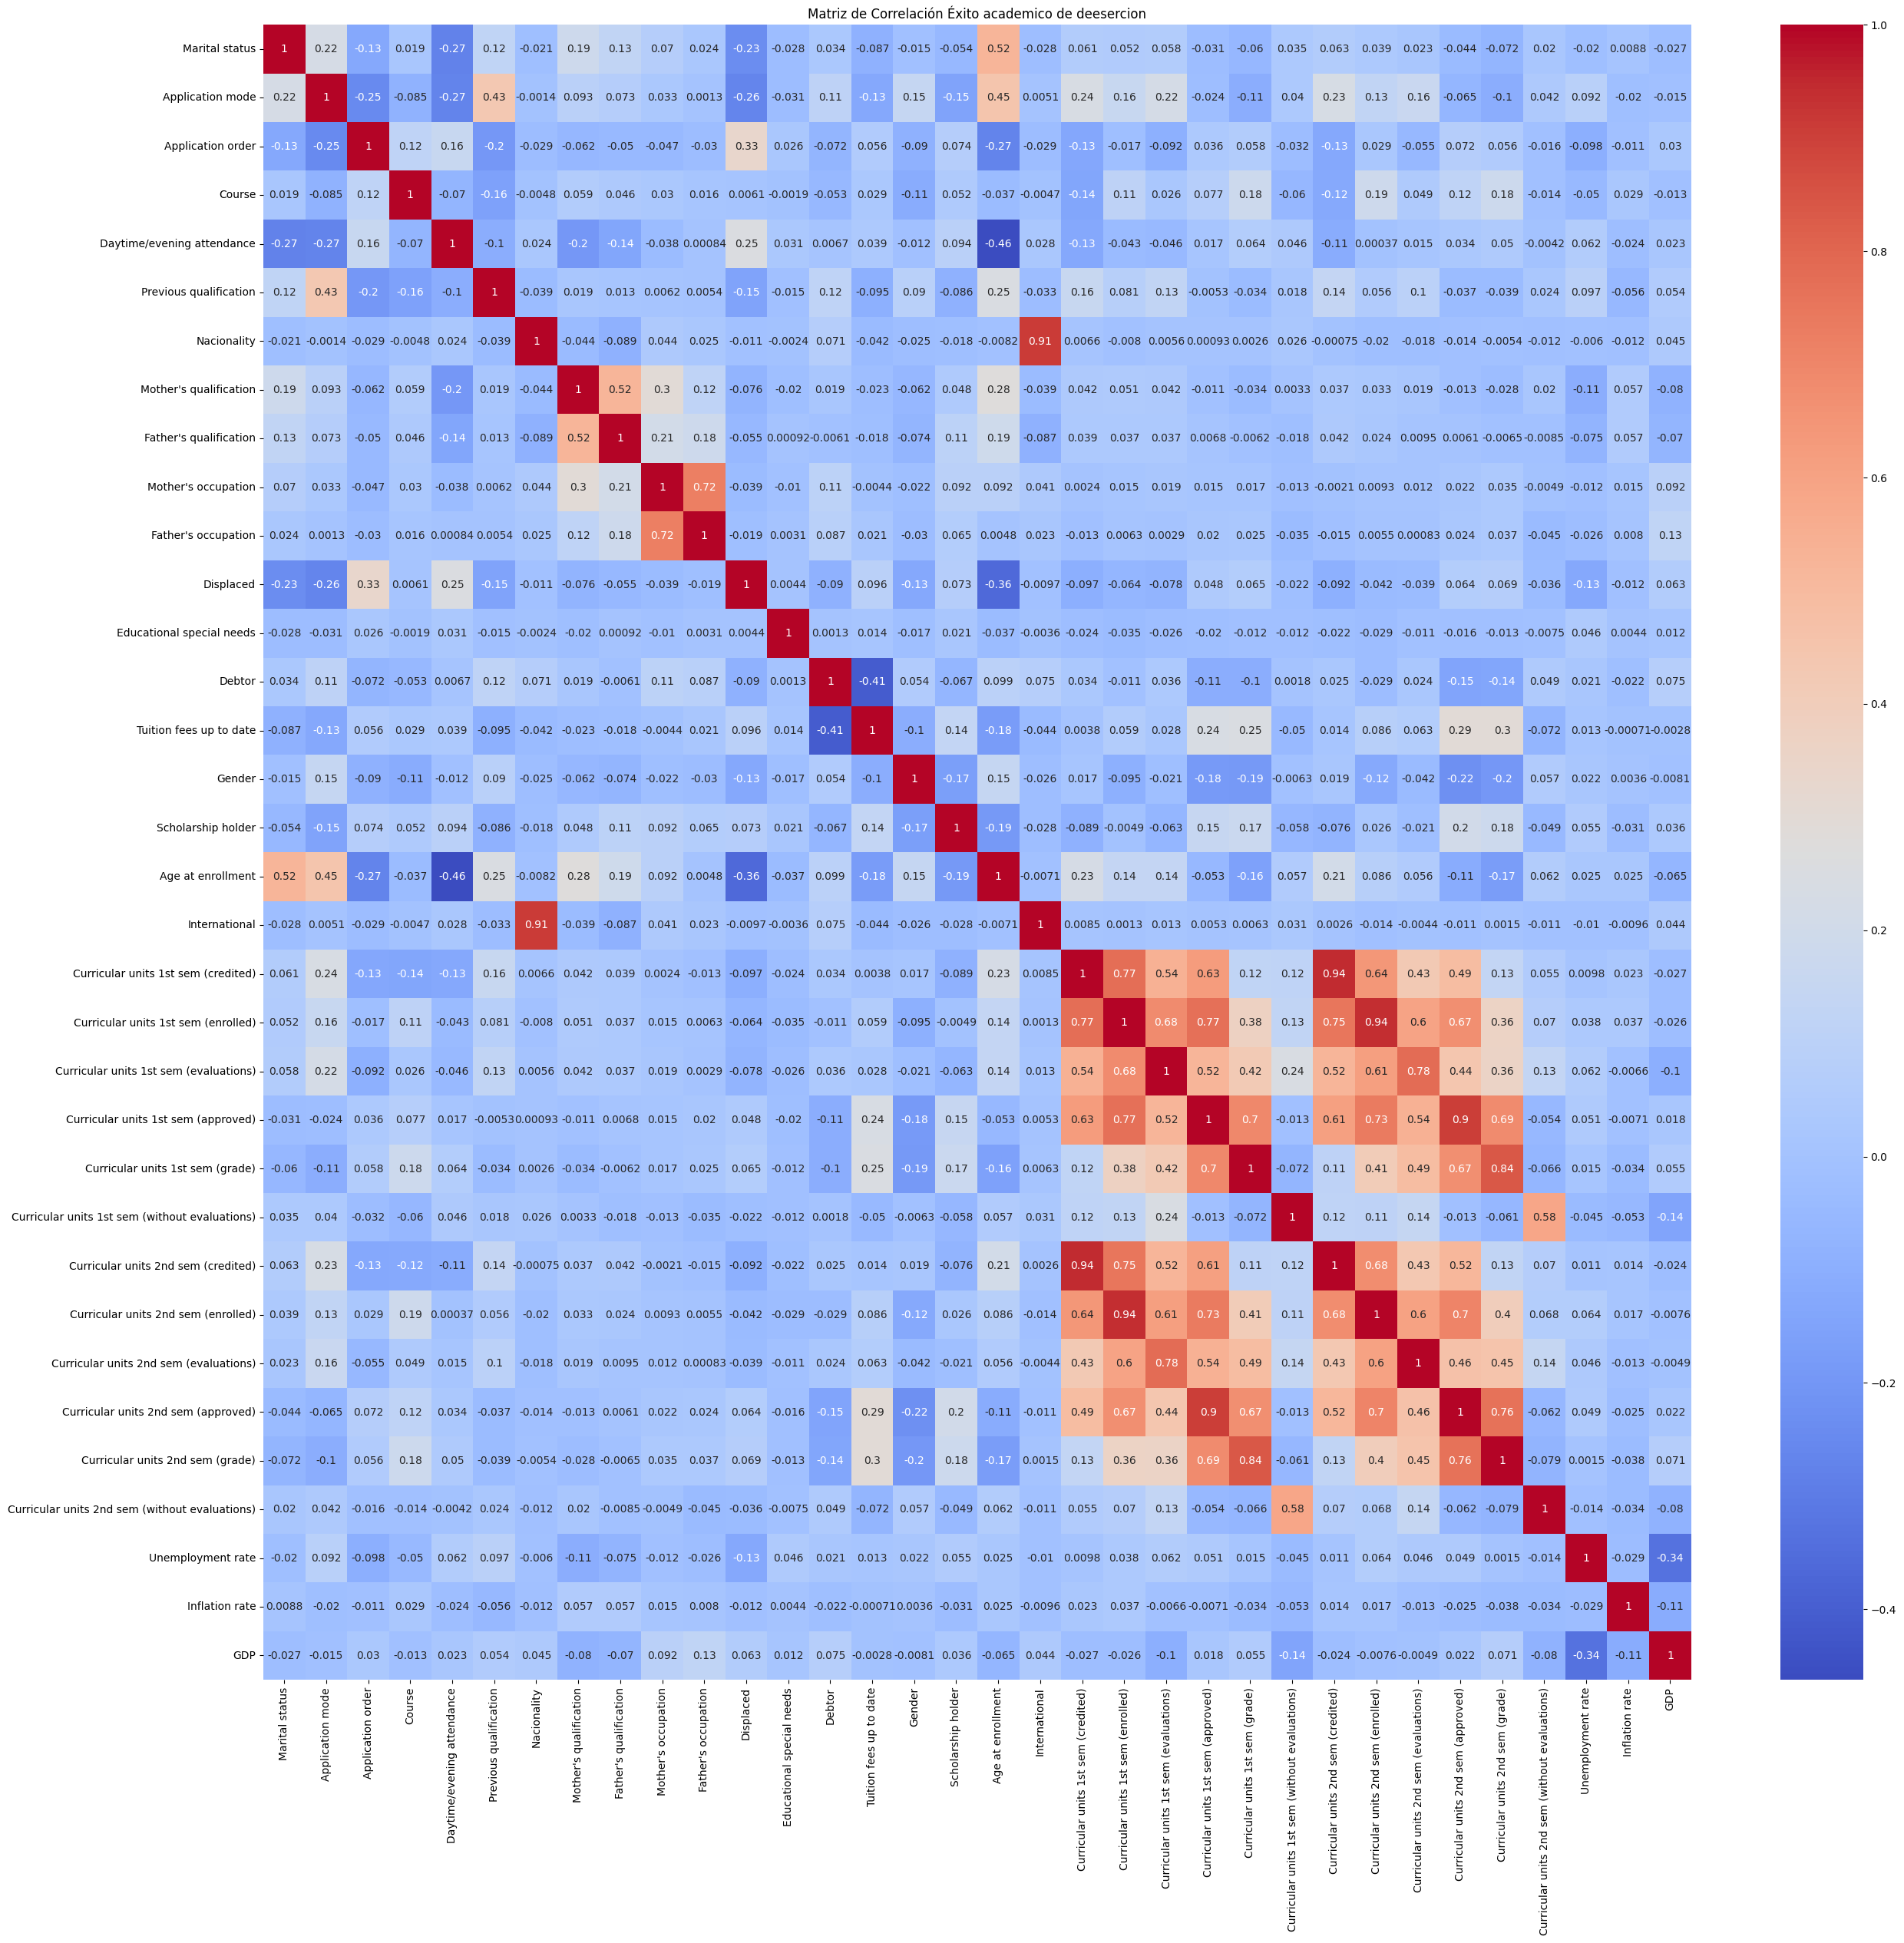

In [ ]:
plt.figure(figsize=(30, 28))
matriz_corr = df_students.select_dtypes(include=[np.number]).corr()
sns.heatmap(matriz_corr, annot=True, cmap='coolwarm')
plt.title('Matriz de Correlación Éxito academico de deesercion')
plt.show()


# Gráfico Analítico de Deserción vs. Calificaciones del 1er Semestre

/tmp/ipykernel_1187/2177786140.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


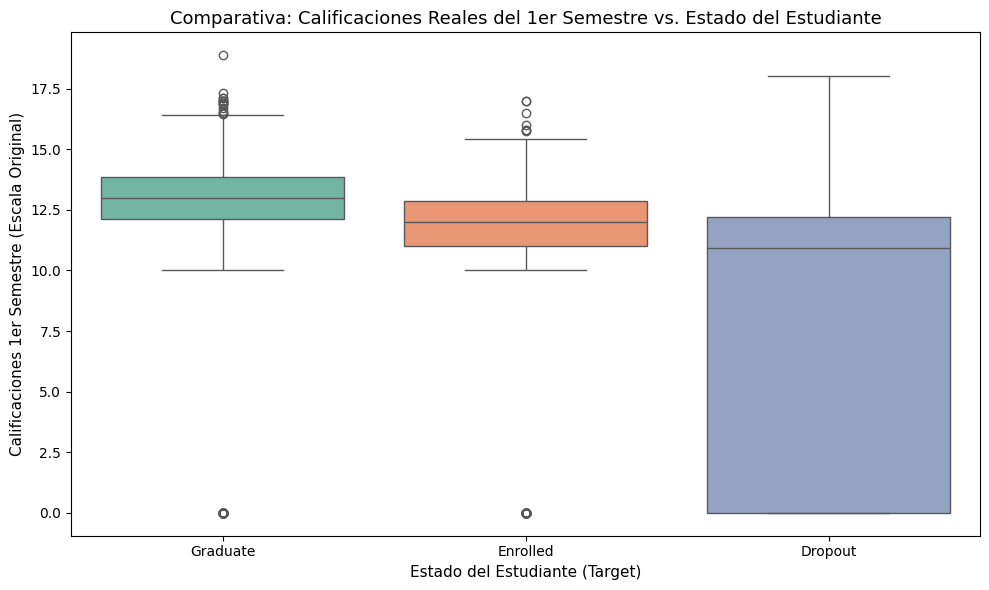

In [ ]:
plt.figure(figsize=(10, 6))

# Usamos df_students limpio para ver las calificaciones reales (sin transformar)
sns.boxplot(
    x='Target',
    y='Curricular units 1st sem (grade)',
    data=df_students,
    palette='Set2',
    order=['Graduate', 'Enrolled', 'Dropout']
)

plt.title('Comparativa: Calificaciones Reales del 1er Semestre vs. Estado del Estudiante', fontsize=13)
plt.xlabel('Estado del Estudiante (Target)', fontsize=11)
plt.ylabel('Calificaciones 1er Semestre (Escala Original)', fontsize=11)

plt.tight_layout()
plt.show()

/tmp/ipykernel_1187/1370171219.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_students, x='Target', y='Unemployment rate', palette='Set2')


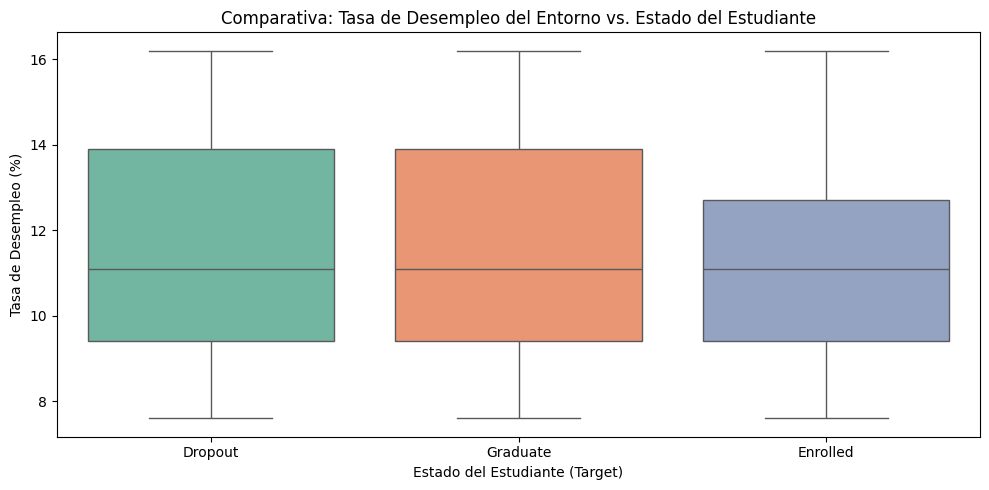

In [ ]:
plt.figure(figsize=(10, 5))

# Usamos un gráfico de caja (boxplot) para comparar una variable que NO sea calificación, por ejemplo: la Tasa de Desempleo vs el Estado del Estudiante
sns.boxplot(data=df_students, x='Target', y='Unemployment rate', palette='Set2')

plt.title('Comparativa: Tasa de Desempleo del Entorno vs. Estado del Estudiante', fontsize=12)
plt.xlabel('Estado del Estudiante (Target)', fontsize=10)
plt.ylabel('Tasa de Desempleo (%)', fontsize=10)

plt.tight_layout()
plt.show()

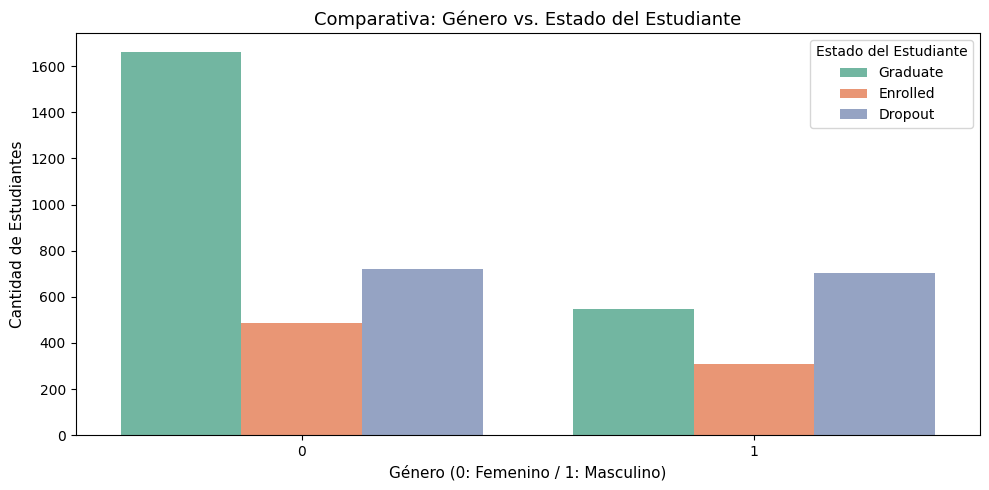

In [ ]:
plt.figure(figsize=(10, 5))

# Gráfico de barras para comparar el Género frente al Estado del Estudiante (Target)
sns.countplot(
    data=df_students,
    x='Gender',
    hue='Target',
    palette='Set2',
    hue_order=['Graduate', 'Enrolled', 'Dropout']
)

plt.title('Comparativa: Género vs. Estado del Estudiante', fontsize=13)
plt.xlabel('Género (0: Femenino / 1: Masculino)', fontsize=11)
plt.ylabel('Cantidad de Estudiantes', fontsize=11)
plt.legend(title='Estado del Estudiante')

plt.tight_layout()
plt.show()

In [ ]:
# Creamos una tabla cruzada limpia entre el nivel de estudios del padre y el estado final del estudiante
tabla_cruzada = pd.crosstab(
    df_students["Father's qualification"],
    df_students['Target'],
    normalize='index'
) * 100

# Mostramos la tabla redondeada a 2 decimales en porcentaje
display(tabla_cruzada.round(2))

Target,Dropout,Enrolled,Graduate
Father's qualification,,,
1,31.08,19.03,49.89
2,32.35,36.76,30.88
3,31.91,21.99,46.10
4,35.90,17.95,46.15
5,55.56,16.67,27.78
6,100.00,0.00,0.00
7,20.00,0.00,80.00
8,100.00,0.00,0.00
9,40.00,0.00,60.00
